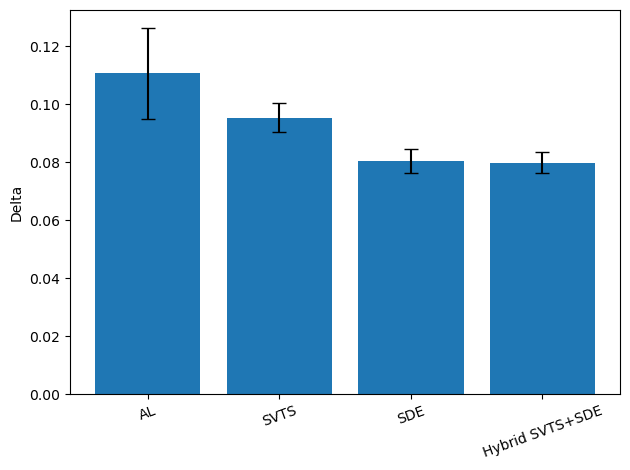

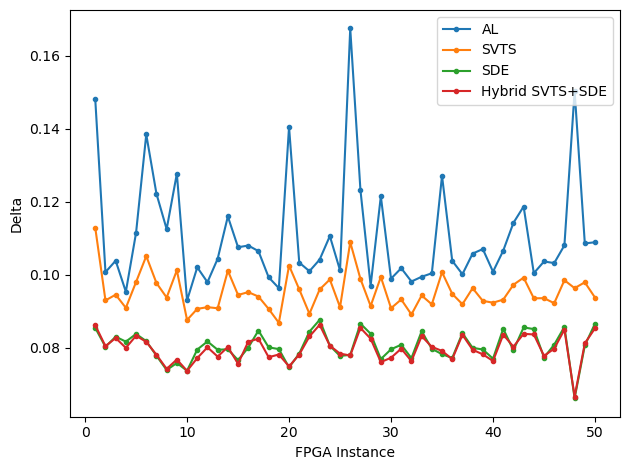

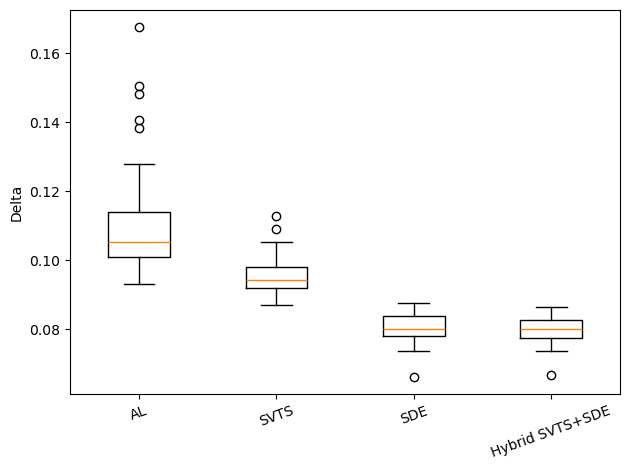

          AL    SVTS     SDE  Hybrid SVTS+SDE
FPGA                                         
1     0.1481  0.1129  0.0855           0.0862
2     0.1008  0.0930  0.0803           0.0805
3     0.1039  0.0946  0.0831           0.0827
4     0.0954  0.0910  0.0817           0.0800
5     0.1115  0.0981  0.0838           0.0834
6     0.1385  0.1052  0.0819           0.0817
7     0.1222  0.0978  0.0779           0.0781
8     0.1126  0.0938  0.0740           0.0743
9     0.1278  0.1013  0.0759           0.0768
10    0.0930  0.0877  0.0738           0.0737
11    0.1021  0.0907  0.0796           0.0772
12    0.0980  0.0912  0.0818           0.0802
13    0.1044  0.0909  0.0795           0.0776
14    0.1160  0.1012  0.0797           0.0803
15    0.1076  0.0945  0.0767           0.0757
16    0.1081  0.0953  0.0801           0.0817
17    0.1065  0.0941  0.0848           0.0825
18    0.0994  0.0907  0.0802           0.0775
19    0.0964  0.0869  0.0797           0.0782
20    0.1405  0.1026  0.0747      

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

BASE = "C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/MY PAPERS/Experiment 2"
METHODS = ["raw_al", "svts", "sde", "hybrid_svts_sde"]
LABELS = ["AL", "SVTS", "SDE", "Hybrid SVTS+SDE"]


def load(method):
    return pd.read_csv(f"{BASE}/{method}/{method}_delta_per_fpga.csv")


# 1. bar chart with error bars
means = [load(m)["Delta"].mean() for m in METHODS]
stds = [load(m)["Delta"].std() for m in METHODS]
plt.figure()
plt.bar(LABELS, means, yerr=stds, capsize=5)
plt.ylabel("Delta")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("bar_error.png", dpi=200)
plt.show()

# 2. line plot per FPGA
plt.figure()
for m, lbl in zip(METHODS, LABELS):
    df = load(m)
    plt.plot(df["FPGA"], df["Delta"], label=lbl, marker="o", markersize=3)
plt.xlabel("FPGA Instance")
plt.ylabel("Delta")
plt.legend()
plt.tight_layout()
plt.savefig("line_fpga.png", dpi=200)
plt.show()

# 3. box plot stability
plt.figure()
data = [load(m)["Delta"] for m in METHODS]
plt.boxplot(data, labels=LABELS)
plt.ylabel("Delta")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("box_stability.png", dpi=200)
plt.show()

# 4. per-FPGA table
table = pd.DataFrame()
for m, lbl in zip(METHODS, LABELS):
    table[lbl] = load(m).set_index("FPGA")["Delta"]
table.loc["AVG."] = table.mean()
print(table.round(4))
table.to_csv("per_fpga_table.csv")


In [6]:
import pandas as pd, matplotlib.pyplot as plt

FILES = {
    "Hybrid SVTS+SDE": "hybrid_svts_sde/hybrid_svts_sde_delta_per_fpga.csv",
    "AL": "raw_al/raw_al_delta_per_fpga.csv",
    "SVTS": "svts/svts_delta_per_fpga.csv",
    "SDE": "sde/sde_delta_per_fpga.csv",
}

plt.figure(figsize=(10, 5))
for method, f in FILES.items():
    df = pd.read_csv(f)
    plt.plot(df.FPGA, df.Delta, marker="o", markersize=3, label=method)

plt.xlabel("FPGA")
plt.ylabel("Delta")
plt.title("Per-FPGA Delta across all methods (FPGA 1-50)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("fig4_per_fpga_delta.png", dpi=200, bbox_inches="tight")
plt.close()


In [9]:
import pandas as pd, matplotlib.pyplot as plt, numpy as np

FPGA_ID = 4
FILES = {
    "Hybrid SVTS+SDE": "hybrid_svts_sde/hybrid_svts_sde_delta_per_path.csv",
    "AL": "raw_al/raw_al_delta_per_path.csv",
    "SVTS": "svts/svts_delta_per_path.csv",
    "SDE": "sde/sde_delta_per_path.csv",
}

data = {}
for method, f in FILES.items():
    df = pd.read_csv(f)
    df = df[df.FPGA == FPGA_ID].sort_values("PATH")
    data[method] = df.Delta.values

paths = np.arange(1, 33)
n_methods = len(FILES)
width = 0.8 / n_methods

plt.figure(figsize=(14, 5))
for i, (method, vals) in enumerate(data.items()):
    plt.bar(paths + i * width, vals, width=width, label=method)

plt.xlabel("Path Index")
plt.ylabel("Delta")
plt.title(f"Per-path Delta comparison, FPGA-{FPGA_ID}, all 32 paths")
plt.xticks(paths)
plt.legend()
plt.grid(alpha=0.3, axis="y")
plt.savefig("fig5_per_path_bar.png", dpi=200, bbox_inches="tight")
plt.close()


Saved box_stability.pdf


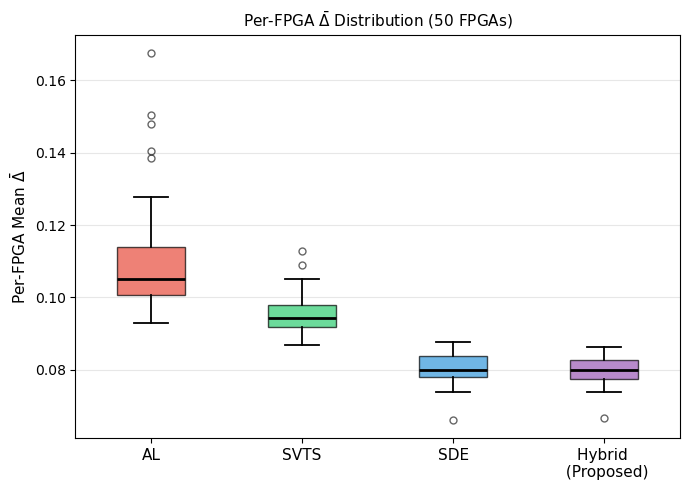

In [13]:
import pandas as pd, matplotlib.pyplot as plt, matplotlib.patches as mpatches

BASE = "C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/MY PAPERS/Experiment 2"
METHODS = ["raw_al", "svts", "sde", "hybrid_svts_sde"]
LABELS = ["AL", "SVTS", "SDE", "Hybrid \n (Proposed)"]
COLORS = ["#E74C3C", "#2ECC71", "#3498DB", "#9B59B6"]


def load(m):
    return pd.read_csv(f"{BASE}/{m}/{m}_delta_per_fpga.csv")


data = [load(m)["Delta"] for m in METHODS]

fig, ax = plt.subplots(figsize=(7, 5))
bp = ax.boxplot(
    data,
    labels=LABELS,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(linewidth=1.3),
    capprops=dict(linewidth=1.3),
    flierprops=dict(marker="o", markersize=5, alpha=0.6),
)

for patch, color in zip(bp["boxes"], COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_ylabel(r"Per-FPGA Mean $\bar{\Delta}$", fontsize=11)
ax.set_title(
    "Per-FPGA $\\bar{\\Delta}$ Distribution (50 FPGAs)",
    fontsize=11,
)
ax.grid(alpha=0.3, axis="y")
ax.tick_params(axis="x", labelsize=11)
fig.tight_layout()
fig.savefig("box_stability.pdf", dpi=200, bbox_inches="tight")
print("Saved box_stability.pdf")


Saved fig5_per_path_bar.pdf


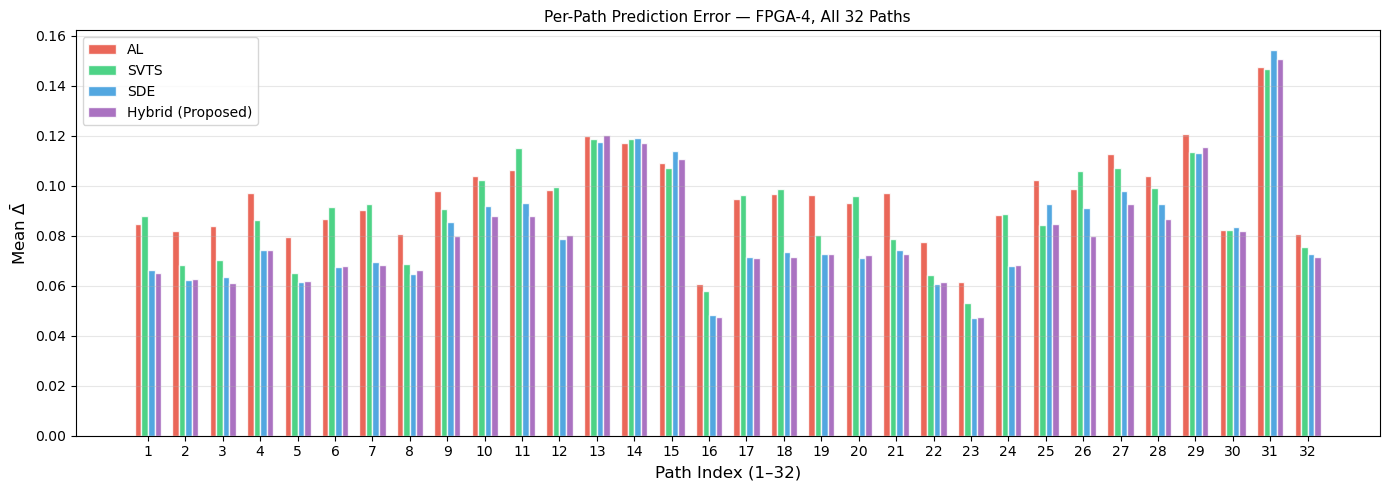

In [14]:
import pandas as pd, matplotlib.pyplot as plt, numpy as np

BASE = "C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/MY PAPERS/Experiment 2"
FPGA_ID = 4
FILES = {
    "AL": "raw_al/raw_al_delta_per_path.csv",
    "SVTS": "svts/svts_delta_per_path.csv",
    "SDE": "sde/sde_delta_per_path.csv",
    "Hybrid (Proposed)": "hybrid_svts_sde/hybrid_svts_sde_delta_per_path.csv",
}
COLORS = {
    "AL": "#E74C3C",
    "SVTS": "#2ECC71",
    "SDE": "#3498DB",
    "Hybrid (Proposed)": "#9B59B6",
}

data = {}
for method, f in FILES.items():
    df = pd.read_csv(f"{BASE}/{f}")
    df = df[df.FPGA == FPGA_ID].sort_values("PATH")
    data[method] = df.Delta.values

paths = np.arange(1, 33)
n_methods = len(FILES)
width = 0.7 / n_methods

fig, ax = plt.subplots(figsize=(14, 5))
for i, (method, vals) in enumerate(data.items()):
    offset = (i - n_methods / 2 + 0.5) * width
    ax.bar(
        paths + offset,
        vals,
        width=width,
        label=method,
        color=COLORS[method],
        alpha=0.85,
        edgecolor="white",
    )

ax.set_xlabel("Path Index (1–32)", fontsize=12)
ax.set_ylabel(r"Mean $\bar{\Delta}$", fontsize=12)
ax.set_title(f"Per-Path Prediction Error — FPGA-{FPGA_ID}, All 32 Paths", fontsize=11)
ax.set_xticks(paths)
ax.legend(fontsize=10)
ax.grid(alpha=0.3, axis="y")

fig.tight_layout()
fig.savefig("fig5_per_path_bar.pdf", dpi=200, bbox_inches="tight")
print("Saved fig5_per_path_bar.pdf")


Saved fig4_per_fpga_delta.pdf


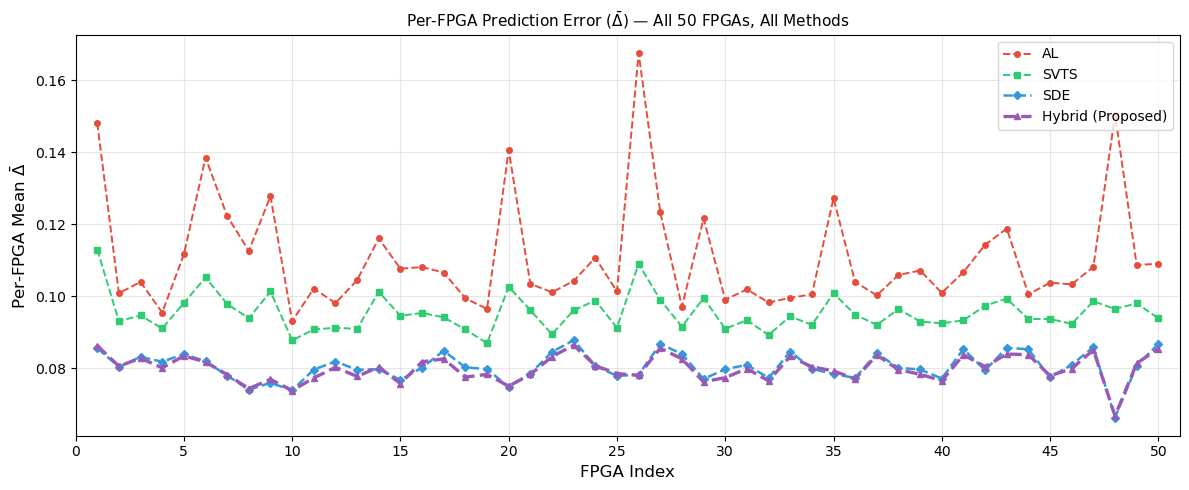

In [15]:
import pandas as pd, matplotlib.pyplot as plt

BASE = "C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/MY PAPERS/Experiment 2"
FILES = {
    "AL": "raw_al/raw_al_delta_per_fpga.csv",
    "SVTS": "svts/svts_delta_per_fpga.csv",
    "SDE": "sde/sde_delta_per_fpga.csv",
    "Hybrid (Proposed)": "hybrid_svts_sde/hybrid_svts_sde_delta_per_fpga.csv",
}
COLORS = {
    "AL": "#E74C3C",
    "SVTS": "#2ECC71",
    "SDE": "#3498DB",
    "Hybrid (Proposed)": "#9B59B6",
}
MARKERS = {"AL": "o", "SVTS": "s", "SDE": "D", "Hybrid (Proposed)": "^"}
LS = {"AL": "--", "SVTS": "--", "SDE": "--", "Hybrid (Proposed)": "--"}
LWS = {"AL": 1.4, "SVTS": 1.4, "SDE": 1.8, "Hybrid (Proposed)": 2.4}

fig, ax = plt.subplots(figsize=(12, 5))

for method, f in FILES.items():
    df = pd.read_csv(f"{BASE}/{f}").sort_values("FPGA")
    ax.plot(
        df["FPGA"],
        df["Delta"],
        color=COLORS[method],
        marker=MARKERS[method],
        linestyle=LS[method],
        linewidth=LWS[method],
        markersize=4,
        label=method,
        zorder=5 if "Hybrid" in method else 3,
    )

ax.set_xlabel("FPGA Index", fontsize=12)
ax.set_ylabel(r"Per-FPGA Mean $\bar{\Delta}$", fontsize=12)
ax.set_title(
    r"Per-FPGA Prediction Error ($\bar{\Delta}$) — All 50 FPGAs, All Methods",
    fontsize=11,
)
ax.set_xlim(1, 51)
ax.set_xticks(range(0, 51, 5))

ax.legend(fontsize=10, loc="upper right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("fig4_per_fpga_delta.pdf", dpi=200, bbox_inches="tight")
print("Saved fig4_per_fpga_delta.pdf")


Saved bar_error.pdf


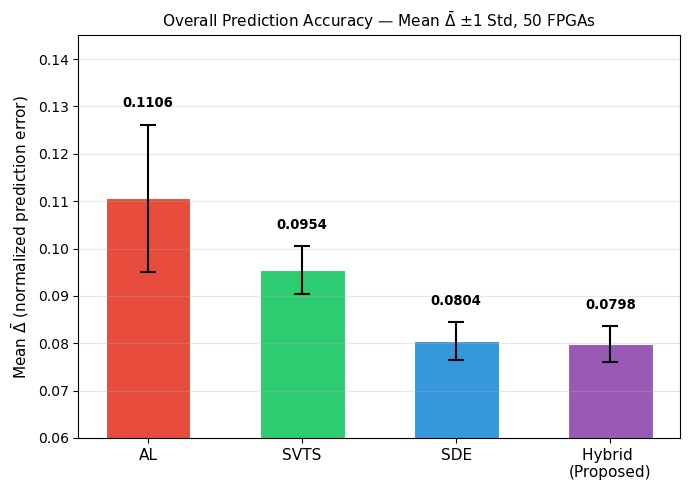

In [16]:
import pandas as pd, matplotlib.pyplot as plt
import numpy as np

BASE = "C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/MY PAPERS/Experiment 2"
METHODS = ["raw_al", "svts", "sde", "hybrid_svts_sde"]
LABELS = ["AL", "SVTS", "SDE", "Hybrid \n(Proposed)"]
COLORS = ["#E74C3C", "#2ECC71", "#3498DB", "#9B59B6"]


def load(m):
    return pd.read_csv(f"{BASE}/{m}/{m}_delta_per_fpga.csv")


means = [load(m)["Delta"].mean() for m in METHODS]
stds = [load(m)["Delta"].std() for m in METHODS]

fig, ax = plt.subplots(figsize=(7, 5))
x = np.arange(len(LABELS))
bars = ax.bar(
    x,
    means,
    yerr=stds,
    capsize=6,
    color=COLORS,
    edgecolor="white",
    linewidth=0.8,
    error_kw=dict(ecolor="black", elinewidth=1.5, capthick=1.5),
    width=0.55,
)

for bar, val, std in zip(bars, means, stds):
    # place label above the error bar
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        val + std + 0.003,
        f"{val:.4f}",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
    )

ax.set_ylim(0.06, 0.145)
ax.set_xticks(x)
ax.set_xticklabels(LABELS, fontsize=11)
ax.set_ylabel(r"Mean $\bar{\Delta}$ (normalized prediction error)", fontsize=11)
ax.set_title(
    r"Overall Prediction Accuracy — Mean $\bar{\Delta}$ $\pm$1 Std, 50 FPGAs",
    fontsize=11,
)
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig("bar_error.pdf", dpi=200, bbox_inches="tight")
print("Saved bar_error.pdf")
